## Análise Exploratória de Dados

In [ ]:
#Bibliotecas para manipulação dos dados
import pandas as pd
import numpy as np

#Bibliotecas para visualização dos dados
import matplotlib.pyplot as plt
import seaborn as sns

# Ferramenta da biblioteca Python que ajuda contar quantas vezes um valor aparece em uma coleção
from collections import Counter


In [50]:
#Carregando a base de dados na variável 'df'
df = pd.read_csv("../data/WineQT.csv")

#Visualização das 5 primeiras linhas da tabela
df.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,Id
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,0
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,1
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,2
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,3
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,4


In [51]:
#Visualização das 5 últimas linhas da tabela
df.tail()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,Id
1138,6.3,0.510,0.13,2.3,0.076,29.0,40.0,0.99574,3.42,0.75,11.0,6,1592
1139,6.8,0.620,0.08,1.9,0.068,28.0,38.0,0.99651,3.42,0.82,9.5,6,1593
1140,6.2,0.600,0.08,2.0,0.090,32.0,44.0,0.99490,3.45,0.58,10.5,5,1594
1141,5.9,0.550,0.10,2.2,0.062,39.0,51.0,0.99512,3.52,0.76,11.2,6,1595
1142,5.9,0.645,0.12,2.0,0.075,32.0,44.0,0.99547,3.57,0.71,10.2,5,1597


In [52]:
#Dimensionalidade do conjunto de dados
df.shape

(1143, 13)

In [53]:
#Visualização das colunas
df.columns

Index(['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar',
       'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density',
       'pH', 'sulphates', 'alcohol', 'quality', 'Id'],
      dtype='str')

In [54]:
#Visualização do tipo de dado de cada coluna
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1143 entries, 0 to 1142
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1143 non-null   float64
 1   volatile acidity      1143 non-null   float64
 2   citric acid           1143 non-null   float64
 3   residual sugar        1143 non-null   float64
 4   chlorides             1143 non-null   float64
 5   free sulfur dioxide   1143 non-null   float64
 6   total sulfur dioxide  1143 non-null   float64
 7   density               1143 non-null   float64
 8   pH                    1143 non-null   float64
 9   sulphates             1143 non-null   float64
 10  alcohol               1143 non-null   float64
 11  quality               1143 non-null   int64  
 12  Id                    1143 non-null   int64  
dtypes: float64(11), int64(2)
memory usage: 116.2 KB


In [ ]:
#Busca de dados nulos no dataset
df.isnull().sum()

fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
Id                      0
wine_quality            0
dtype: int64

In [227]:
#Busca de dados duplicados nas colunas, tirando coluna Id
repeated_rows = df[
    df.duplicated(
        subset=df.columns.drop("Id"),
        keep=False
    )
].sort_values("Id")

repeated_rows

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,Id,wine_quality
0,7.4,0.700,0.00,1.90,0.076,11.0,34.0,0.99780,3.51,0.56,9.4,5,0,False
4,7.4,0.700,0.00,1.90,0.076,11.0,34.0,0.99780,3.51,0.56,9.4,5,4,False
45,7.2,0.725,0.05,4.65,0.086,4.0,11.0,0.99620,3.41,0.39,10.9,5,64,False
46,7.2,0.725,0.05,4.65,0.086,4.0,11.0,0.99620,3.41,0.39,10.9,5,65,False
59,8.6,0.490,0.28,1.90,0.110,20.0,136.0,0.99720,2.93,1.95,9.9,6,86,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1113,7.8,0.600,0.26,2.00,0.080,31.0,131.0,0.99622,3.21,0.52,9.9,5,1560,False
1114,7.8,0.600,0.26,2.00,0.080,31.0,131.0,0.99622,3.21,0.52,9.9,5,1561,False
1115,7.2,0.695,0.13,2.00,0.076,12.0,20.0,0.99546,3.29,0.54,10.1,5,1562,False
1116,7.2,0.695,0.13,2.00,0.076,12.0,20.0,0.99546,3.29,0.54,10.1,5,1563,False


In [ ]:
# Agrupando os IDs das linhas repetidas
id_groups = (
    repeated_rows
    .groupby(list(df.columns.drop("Id")))["Id"]
    .agg(list) # agg agrega os valores de cada grupo em uma lista
    .reset_index(name="IDs") #reset a coluna ID para mostrar os IDs de cada grupamento
)

id_groups

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,wine_quality,IDs
0,5.2,0.340,0.00,1.8,0.050,27.0,63.0,0.99160,3.68,0.79,14.0,6,False,"[142, 144]"
1,6.0,0.500,0.00,1.4,0.057,15.0,26.0,0.99448,3.36,0.45,9.5,5,False,"[1336, 1337, 1338]"
2,6.0,0.510,0.00,2.1,0.064,40.0,54.0,0.99500,3.54,0.93,10.7,6,False,"[1407, 1409]"
3,6.4,0.570,0.02,1.8,0.067,4.0,11.0,0.99700,3.46,0.68,9.5,5,False,"[727, 728]"
4,6.4,0.640,0.21,1.8,0.081,14.0,31.0,0.99689,3.59,0.66,9.8,5,False,"[846, 848]"
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
109,12.7,0.600,0.49,2.8,0.075,5.0,19.0,0.99940,3.14,0.57,11.4,5,False,"[560, 565]"
110,12.8,0.300,0.74,2.6,0.095,9.0,28.0,0.99940,3.20,0.77,10.8,7,True,"[205, 206]"
111,12.8,0.615,0.66,5.8,0.083,7.0,42.0,1.00220,3.07,0.73,10.0,7,True,"[364, 366]"
112,13.0,0.470,0.49,4.3,0.085,6.0,47.0,1.00210,3.30,0.68,12.7,6,False,"[559, 564]"


In [ ]:
# Intervalo entre os IDs
id_groups = (
    repeated_rows
    .groupby(list(df.columns.drop("Id")))["Id"]
    .agg(list)
    .reset_index(name="IDs")
)

id_groups["ID differences"] = id_groups["IDs"].apply(
    lambda ids: [
        ids[i + 1] - ids[i]
        for i in range(len(ids) - 1)
    ] # aplicando uma função que faz o cálculo da diferença entre um ID e o ID seguinte do grupamento
)

id_groups[["IDs", "ID differences"]]

,IDs,ID differences
0,"[142, 144]",[2]
1,"[1336, 1337, 1338]","[1, 1]"
2,"[1407, 1409]",[2]
3,"[727, 728]",[1]
4,"[846, 848]",[2]
...,...,...
109,"[560, 565]",[5]
110,"[205, 206]",[1]
111,"[364, 366]",[2]
112,"[559, 564]",[5]


In [ ]:
# Contagem de todas as diferenças entre IDs
difference_counts = Counter(
    difference
    for differences in id_groups["ID differences"]
    for difference in differences
)

print("Quantidade de ocorrências por diferença entre IDs:")
print(pd.Series(difference_counts).sort_index())

Quantidade de ocorrências por diferença entre IDs:
1    45
2    37
3    13
4    14
5     7
6     4
7     2
8     3
dtype: int64


In [256]:
# Analisando se existe padrões de medida que se repetem mais que 3 vezes no dataset
(df.groupby(df.columns.drop("Id").tolist()).size() > 3).any()

np.True_

In [ ]:
# Visualização dos dados que repetem mais que 3 vezes no dataset e suas posições no dataset
repeated_rows = df[
    df.groupby(df.columns.drop("Id").tolist())["Id"]
    .transform("size") > 3
].sort_values("Id")

repeated_rows

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,Id,wine_quality
937,6.7,0.46,0.24,1.7,0.077,18.0,34.0,0.99480,3.39,0.60,10.6,6,1324,False
938,6.7,0.46,0.24,1.7,0.077,18.0,34.0,0.99480,3.39,0.60,10.6,6,1325,False
939,6.7,0.46,0.24,1.7,0.077,18.0,34.0,0.99480,3.39,0.60,10.6,6,1326,False
940,6.7,0.46,0.24,1.7,0.077,18.0,34.0,0.99480,3.39,0.60,10.6,6,1327,False
952,7.5,0.51,0.02,1.7,0.084,13.0,31.0,0.99538,3.36,0.54,10.5,6,1339,False
953,7.5,0.51,0.02,1.7,0.084,13.0,31.0,0.99538,3.36,0.54,10.5,6,1340,False
954,7.5,0.51,0.02,1.7,0.084,13.0,31.0,0.99538,3.36,0.54,10.5,6,1341,False
955,7.5,0.51,0.02,1.7,0.084,13.0,31.0,0.99538,3.36,0.54,10.5,6,1343,False


In [195]:
# Quantidade de colunas que têm medidas duplicadas
df.duplicated(subset=df.columns.drop("Id")).sum()

np.int64(125)

In [221]:
# Quantidade de padrões distintos de medidas e qualidade que se repetem
unique_patterns = df.loc[duplicate_mask].drop_duplicates(
    subset=df.columns.drop("Id")
).shape[0]

print("Quantidade de padrões distintos de medidas e qualidade que se repetem:", unique_patterns)

Quantidade de padrões distintos de medidas e qualidade que se repetem: 114


## Dataset Overview
O dataset possui **1143** linhas e **13** colunas.
- Não há dados nulos.
- O dataset possui 239 linhas que pertencem a padrões repetidos, incluindo a primeira ocorrência de cada padrão. 
- Dentre as 239 linhas encontradas, 114 linhas são de primeira ocorrência de cada padrão repetido e 125 linhas repetem um padrão já encontrado.  
  
Analisando as linhas que repetem padrões de medidas e qualidade, observamos que:
1. As linhas que têm valores idênticos tendem a estar próximas umas das outras na sequência de IDs, sendo 45 dessas ocorrências de IDs consecutivos;
2. Das 125 linhas que repetem um padrão de medidas e qualidade, 109 apresentam diferenças inferiores a cinco entre os IDs;
3. As variáveis apresentam valores numéricos contínuos, incluindo valores decimais com várias casas;
4. Dois padrões de medida e qualidade aparecem quatro vezes no dataset. Seus IDs têm diferença de um ou dois entre eles.  
  
Com base nessas observações, existe a possibilidade de os registros repetidos serem dados duplicados.  
Como a presença de dados duplicados pode influenciar e distorcer modelos preditivos, foram removidas as repetições e mantidas apenas uma ocorrência de cada padrão. 

In [269]:
# 1. Preservar o dataset original
df_original = df.copy()

# 2. Remoção dos dados repetidos, mantendo apenas um de cada padrão
df_clean = df_original.drop_duplicates(
    subset=df_original.columns.drop("Id"),
    keep="first"
)

df_clean.shape

(1018, 14)

Após a remoção dos dados repetidos, o dataset apresenta 1018 registros.

In [270]:
#Contagem de quantos vinhos existe em cada nota em ordem crescente
df_wine_quantity_per_note = df_clean["quality"].value_counts().sort_index()
df_wine_quantity_per_note

quality
3      6
4     33
5    433
6    409
7    122
8     15
Name: count, dtype: int64

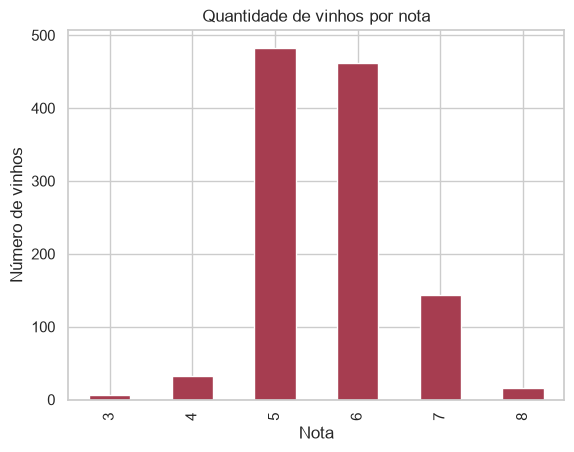

In [258]:
df_wine_quantity_per_note.plot(kind="bar", color="#A63D50")
plt.xlabel("Nota")
plt.ylabel("Número de vinhos")
plt.title("Quantidade de vinhos por nota")
plt.show()

In [275]:
#Porcentagem de vinhos em cada nota
df_percentage = df_clean["quality"].value_counts(normalize=True).sort_index() *100
df_percentage

quality
3     0.589391
4     3.241650
5    42.534381
6    40.176817
7    11.984283
8     1.473477
Name: proportion, dtype: float64

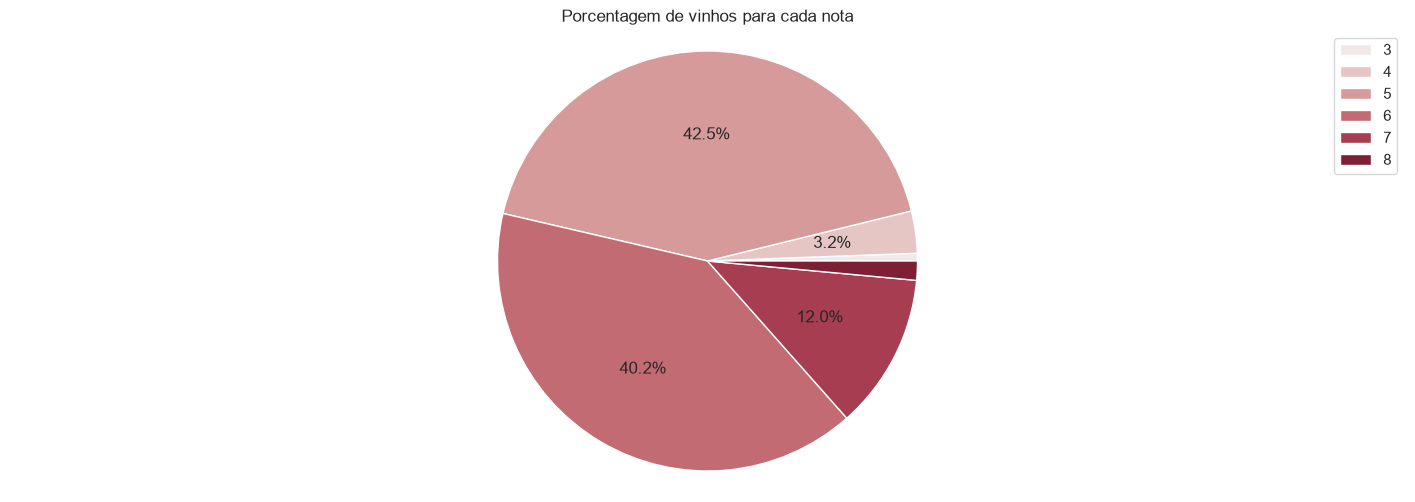

In [276]:
# Gráfico com a porcentagem de vinhos em cada nota
labels = df_percentage.index.tolist()
sizes = df_percentage.values.tolist()


figura, grafico = plt.subplots(figsize=(18,6))

colors = [
    "#F2E8E8",  # quality 3
    "#E6C5C5",  # quality 4
    "#D69A9A",  # quality 5
    "#C26B72",  # quality 6
    "#A63D50",  # quality 7
    "#7D1F35",  # quality 8
]
# para que apareça a % de todos no gráfico:
# grafico.pie(sizes, autopct="%1.1f%%", colors=colors)

# para que apareça apenas porcentagens acima de 3%:
def show_percentage(pct):
    return f"{pct:.1f}%" if pct >= 3 else ""

grafico.pie(
    sizes,
    autopct=show_percentage,
    colors=colors
)

grafico.axis('equal')
plt.title("Porcentagem de vinhos para cada nota")
plt.legend(labels, loc="best")
plt.show()

Mais de 90% dos vinhos classificados têm nota entre 5 e 7.

In [277]:
#Estatísticas descritivas de cada coluna
df_clean.describe().T

,count,mean,std,min,25%,50%,75%,max
fixed acidity,1018.0,8.288507,1.741324,4.60000,7.100000,7.900000,9.100000,15.90000
volatile acidity,1018.0,0.533541,0.183167,0.12000,0.390000,0.520000,0.645000,1.58000
citric acid,1018.0,0.268802,0.196229,0.00000,0.090000,0.250000,0.420000,1.00000
residual sugar,1018.0,2.524411,1.314850,0.90000,1.900000,2.200000,2.600000,15.50000
chlorides,1018.0,0.087187,0.048506,0.01200,0.070000,0.079000,0.090000,0.61100
free sulfur dioxide,1018.0,15.648821,10.176525,1.00000,7.000000,13.000000,21.000000,68.00000
total sulfur dioxide,1018.0,46.325639,33.123533,6.00000,21.000000,38.000000,62.000000,289.00000
density,1018.0,0.996700,0.001916,0.99007,0.995572,0.996665,0.997827,1.00369
pH,1018.0,3.311503,0.157775,2.74000,3.210000,3.310000,3.400000,4.01000
sulphates,1018.0,0.656817,0.167542,0.33000,0.550000,0.620000,0.720000,2.00000


As colunas "fixed acidity", "residual sugar", "free sulfur dioxide", "total sulfur dioxide" apresentaram valores máximos discrepantes com relação aos valores das médias.

# Visualização da concentração dos dados e outliers das colunas que apresentaram valores discrepantes

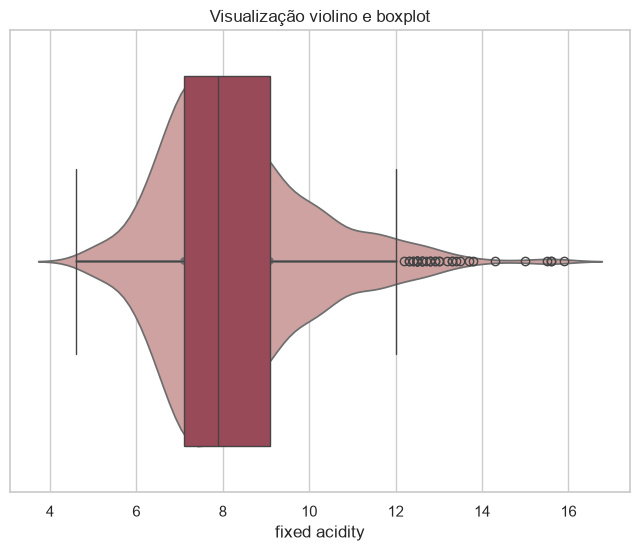

In [278]:
#Fazendo gráfico de boxplot e violino para visualização de possíveis outliers
fig, ax = plt.subplots(figsize=(8,6))
sns.violinplot(x="fixed acidity", data=df_clean, ax=ax, color="#D69A9A")
sns.boxplot(x="fixed acidity", data=df_clean, ax=ax, whis=1.5, color="#A63D50")
ax.set_title("Visualização violino e boxplot")
plt.show()

Os pontos que aparecem acima do valor máximo são outliers.
O gráfico de violino mostra a concentração e distribuição dos dados

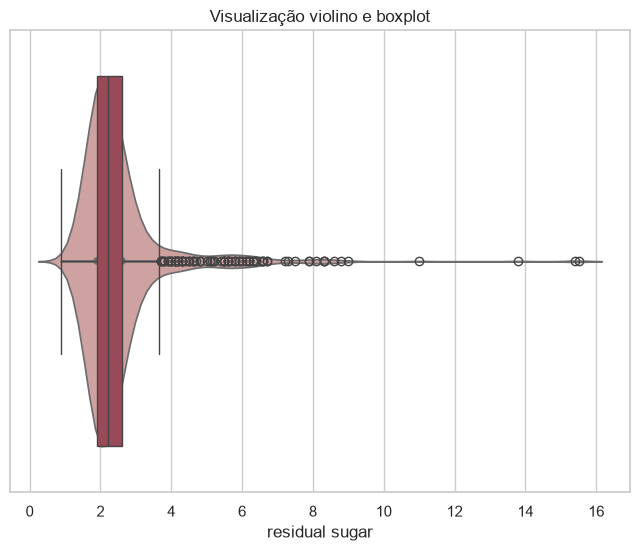

In [279]:
#Fazendo gráfico de boxplot e violino para visualização de possíveis outliers
fig, ax = plt.subplots(figsize=(8,6))
sns.violinplot(x="residual sugar", data=df_clean, ax=ax, color="#D69A9A")
sns.boxplot(x="residual sugar", data=df_clean, ax=ax, whis=1.5, color="#A63D50")
ax.set_title("Visualização violino e boxplot")
plt.show()

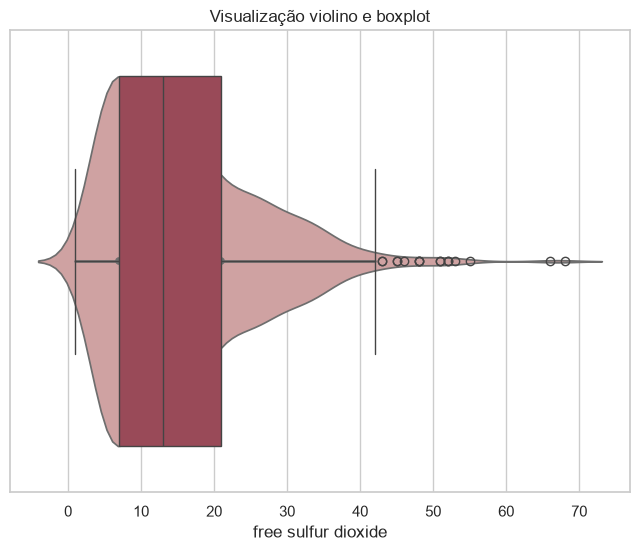

In [280]:
#Fazendo gráfico de boxplot e violino para visualização de possíveis outliers
fig, ax = plt.subplots(figsize=(8,6))
sns.violinplot(x="free sulfur dioxide", data=df_clean, ax=ax, color="#D69A9A")
sns.boxplot(x="free sulfur dioxide", data=df_clean, ax=ax, whis=1.5, color="#A63D50")
ax.set_title("Visualização violino e boxplot")
plt.show()

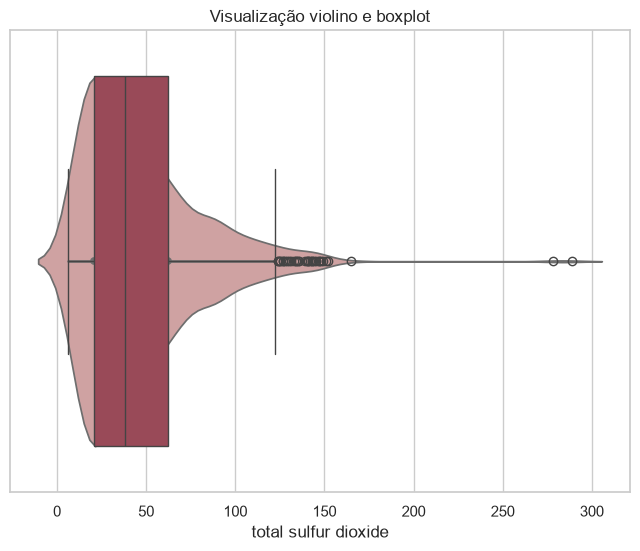

In [281]:
#Fazendo gráfico de boxplot e violino para visualização de possíveis outliers
fig, ax = plt.subplots(figsize=(8,6))
sns.violinplot(x="total sulfur dioxide", data=df_clean, ax=ax, color="#D69A9A")
sns.boxplot(x="total sulfur dioxide", data=df_clean, ax=ax, whis=1.5, color="#A63D50")
ax.set_title("Visualização violino e boxplot")
plt.show()

In [284]:
features = [
    "fixed acidity",
    "residual sugar",
    "free sulfur dioxide",
    "total sulfur dioxide"
]

outlier_summary = []

for column in features:
    Q1 = df_clean[column].quantile(0.25)
    Q3 = df_clean[column].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df_clean[
        (df_clean[column] < lower_bound) |
        (df_clean[column] > upper_bound)
    ]

    outlier_summary.append({
        "feature": column,
        "lower_bound": lower_bound,
        "upper_bound": upper_bound,
        "outliers": len(outliers),
        "percentage": len(outliers) / len(df_clean) * 100
    })

outlier_summary = pd.DataFrame(outlier_summary)

outlier_summary

,feature,lower_bound,upper_bound,outliers,percentage
0,fixed acidity,4.10,12.10,37,3.634578
1,residual sugar,0.85,3.65,95,9.332024
2,free sulfur dioxide,-14.00,42.00,16,1.571709
3,total sulfur dioxide,-40.50,123.50,33,3.241650


In [287]:
# mostrando os maiores valores
df_clean.nlargest(5, "total sulfur dioxide")

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,Id,wine_quality
761,7.9,0.300,0.68,8.3,0.050,37.5,289.0,0.99316,3.01,0.51,12.3,7,1081,True
760,7.9,0.300,0.68,8.3,0.050,37.5,278.0,0.99316,3.01,0.51,12.3,7,1079,True
249,6.1,0.210,0.40,1.4,0.066,40.5,165.0,0.99120,3.25,0.59,11.9,6,354,False
485,9.8,0.980,0.32,2.3,0.078,35.0,152.0,0.99800,3.25,0.48,9.4,5,684,False
366,8.5,0.655,0.49,6.1,0.122,34.0,151.0,1.00100,3.31,1.14,9.3,5,515,False


In [300]:
# mostrando os maiores valores
df_clean.nlargest(5, "free sulfur dioxide")

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,Id,wine_quality
275,6.6,0.735,0.02,7.9,0.122,68.0,124.0,0.99940,3.47,0.53,9.9,5,396,False
1111,6.9,0.630,0.33,6.7,0.235,66.0,115.0,0.99787,3.22,0.56,9.5,5,1558,False
1022,10.2,0.540,0.37,15.4,0.214,55.0,95.0,1.00369,3.18,0.77,9.0,6,1434,False
654,8.6,0.220,0.36,1.9,0.064,53.0,77.0,0.99604,3.47,0.87,11.0,7,925,True
655,9.4,0.240,0.33,2.3,0.061,52.0,73.0,0.99786,3.47,0.90,10.2,6,926,False


In [301]:
# mostrando os maiores valores
df_clean.nlargest(5, "residual sugar")

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,Id,wine_quality
339,10.6,0.28,0.39,15.5,0.069,6.0,23.0,1.00260,3.12,0.66,9.2,5,480,False
1022,10.2,0.54,0.37,15.4,0.214,55.0,95.0,1.00369,3.18,0.77,9.0,6,1434,False
1051,9.9,0.50,0.50,13.8,0.205,48.0,82.0,1.00242,3.16,0.75,8.8,5,1474,False
230,10.0,0.49,0.20,11.0,0.071,13.0,50.0,1.00150,3.16,0.69,9.2,6,324,False
644,9.1,0.28,0.46,9.0,0.114,3.0,9.0,0.99901,3.18,0.60,10.9,6,911,False


In [302]:
# mostrando os maiores valores
df_clean.nlargest(5, "fixed acidity")

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,Id,wine_quality
462,15.9,0.360,0.65,7.5,0.096,22.0,71.0,0.99760,2.98,0.84,14.9,5,652,False
311,15.6,0.685,0.76,3.7,0.100,6.0,43.0,1.00320,2.95,0.68,11.2,7,442,True
399,15.6,0.645,0.49,4.2,0.095,10.0,23.0,1.00315,2.92,0.74,11.1,5,557,False
397,15.5,0.645,0.49,4.2,0.095,10.0,23.0,1.00315,2.92,0.74,11.1,5,554,False
170,15.0,0.210,0.44,2.2,0.075,10.0,24.0,1.00005,3.07,0.84,9.2,7,243,True


Foi identificado um par de registros (IDs 1079 e 1081) com valores idênticos em todas as variáveis, exceto total sulfur dioxide, que os valores registrados são 278.0 e 289.0.  
O mesmo ocorre com os registros de ID 554 e 557 que apresentam valores idênticos para todas as variáveis, exceto para fixed acidity, cujos valores são 15.5 e 15.6.  
  
A semelhança entre os registros e proximidade dos IDs levantam a hipótese de duplicação de dados com possíveis erros de digitação. Entretanto, não há informações sobre a origem dos registros ou medições das amostras que permitam confirmar essa hipótese ou determinar qual é o valor correto a ser mantido no dataset. Sendo assim, os registros serão mantidos no dataset.

# Classificando os vinhos de acordo com a nota

In [290]:
# função para classificar os vinhos como high_quality ou low/medium_quality a partir da nota

def wine_quality_classification(df_clean):
    if df_clean["quality"] >= 7.0:
        return True
    else:
        return False

In [291]:
# Aplicando a função criada para classificar os vinhos no dataset e criando uma coluna no df com a classificação
df_clean["wine_quality"] = df_clean.apply(wine_quality_classification, axis=1)
df_clean.head(5)

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,Id,wine_quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,0,False
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,1,False
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,2,False
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,3,False
5,7.4,0.66,0.00,1.8,0.075,13.0,40.0,0.9978,3.51,0.56,9.4,5,5,False


In [293]:
# Contagem de vinhos de alta qualidade e vinhos de baixa/média qualidade
df_clean.groupby("wine_quality")["wine_quality"].count()

wine_quality
False    881
True     137
Name: wine_quality, dtype: int64